In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report

root = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent

df = (
    pd.read_csv(root / "data" / "reviews.csv")
    .drop_duplicates()
    .reset_index(drop=True)
)

X = df["text_"].astype(str)
y = df["label"].astype(str).str.strip()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset size:", len(df))
print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("Labels:", y.value_counts().to_dict())

Dataset size: 40420
Training reviews: 32336
Testing reviews: 8084
Labels: {'OR': 20215, 'CG': 20205}


In [2]:
def drop_trailing_fragment(text):
    text = re.sub(r"([.!?])([A-Za-z])", r"\1 \2", str(text))
    if re.search(r"[.!?]", text):
        text = re.sub(r"[^.!?]*$", "", text)
    return re.sub(r"\s+", " ", text).strip()


X_train_D = X_train.apply(drop_trailing_fragment)
X_test_D = X_test.apply(drop_trailing_fragment)

print("Training reviews:", len(X_train_D))
print("Test reviews:", len(X_test_D))
print("\nOriginal review:")
print(X_train.iloc[0][:200])
print("\nTransformed review:")
print(X_train_D.iloc[0][:200])

Training reviews: 32336
Test reviews: 8084

Original review:
Much like the card case this is a well built wallet. The seams seem strong as well as the leather itself. I love the variety of colors this company offers as well. This would be a great option if you 

Transformed review:
Much like the card case this is a well built wallet. The seams seem strong as well as the leather itself. I love the variety of colors this company offers as well. This would be a great option if you 


In [3]:
tfidf = TfidfVectorizer(
    lowercase=True,
    max_features=5000,
    ngram_range=(1, 2)
)

Xtr_sparse = tfidf.fit_transform(X_train_D)
Xte_sparse = tfidf.transform(X_test_D)

print("Training TF-IDF shape:", Xtr_sparse.shape)
print("Testing TF-IDF shape:", Xte_sparse.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (32336, 5000)
Testing TF-IDF shape: (8084, 5000)
Vocabulary size: 5000


In [4]:
# Convert sparse TF-IDF matrices to float32 arrays
Xtr = Xtr_sparse.toarray().astype("float32")
Xte = Xte_sparse.toarray().astype("float32")

# Convert labels into binary values:
# OR = 1, CG = 0
ytr = (y_train == "OR").astype("int32").to_numpy()
yte = (y_test == "OR").astype("int32").to_numpy()

print("Training features:", Xtr.shape)
print("Testing features:", Xte.shape)
print("Training labels:", ytr.shape)
print("Testing labels:", yte.shape)
print("Training feature data type:", Xtr.dtype)
print("Training label counts:", np.bincount(ytr))

Training features: (32336, 5000)
Testing features: (8084, 5000)
Training labels: (32336,)
Testing labels: (8084,)
Training feature data type: float32
Training label counts: [16164 16172]


In [5]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping

def build_mlp(optimizer_name="adam", dropout_rate=0.0, l2_strength=0.0):
    tf.keras.utils.set_random_seed(42)

    model = keras.Sequential([
        keras.Input(shape=(5000,)),

        layers.Dense(
            64,
            activation="relu",
            kernel_regularizer=(
                regularizers.l2(l2_strength) if l2_strength > 0 else None
            )
        ),

        layers.Dropout(dropout_rate),

        layers.Dense(1, activation="sigmoid")
    ])

    if optimizer_name == "sgd":
        optimizer = keras.optimizers.SGD(learning_rate=0.01)
    else:
        optimizer = keras.optimizers.Adam(learning_rate=0.001)

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


print("MLP model builder is ready!")

MLP model builder is ready!


In [6]:
experiments = [
    {
        "name": "SGD Baseline",
        "optimizer": "sgd",
        "dropout": 0.0,
        "l2": 0.0
    },
    {
        "name": "Adam Baseline",
        "optimizer": "adam",
        "dropout": 0.0,
        "l2": 0.0
    },
    {
        "name": "Adam + Dropout 0.4",
        "optimizer": "adam",
        "dropout": 0.4,
        "l2": 0.0
    },
    {
        "name": "Adam + L2 0.001",
        "optimizer": "adam",
        "dropout": 0.0,
        "l2": 0.001
    }
]

results = []
histories = {}
trained_models = {}

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

for exp in experiments:
    print(f"\nTraining: {exp['name']}")

    model = build_mlp(
        optimizer_name=exp["optimizer"],
        dropout_rate=exp["dropout"],
        l2_strength=exp["l2"]
    )

    history = model.fit(
        Xtr,
        ytr,
        validation_split=0.20,
        epochs=12,
        batch_size=256,
        callbacks=[early_stopping],
        verbose=1
    )

    test_loss, test_accuracy = model.evaluate(
        Xte, yte, verbose=0
    )

    predictions = (model.predict(Xte, verbose=0).ravel() >= 0.5).astype(int)

    results.append({
        "Model": exp["name"],
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss,
        "Best Validation Accuracy": max(history.history["val_accuracy"]),
        "Epochs Trained": len(history.history["loss"])
    })

    histories[exp["name"]] = history.history
    trained_models[exp["name"]] = model

    print(f"Test accuracy: {test_accuracy:.4f}")


Training: SGD Baseline
Epoch 1/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5003 - loss: 0.6932 - val_accuracy: 0.5209 - val_loss: 0.6928
Epoch 2/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5286 - loss: 0.6926 - val_accuracy: 0.5499 - val_loss: 0.6922
Epoch 3/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5549 - loss: 0.6920 - val_accuracy: 0.5720 - val_loss: 0.6916
Epoch 4/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5760 - loss: 0.6914 - val_accuracy: 0.5914 - val_loss: 0.6910
Epoch 5/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5990 - loss: 0.6908 - val_accuracy: 0.6090 - val_loss: 0.6904
Epoch 6/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6190 - loss: 0.6902 - val_accuracy: 0.6279 - val_loss: 0.6897
Epoch 7/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6399 - loss: 0.6895 - val_accuracy: 0.6419 - val_loss: 0.6891
Epoch 8/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6569 - loss: 0

In [7]:
mlp_results = pd.DataFrame(results)
mlp_results = mlp_results.sort_values(
    "Test Accuracy", ascending=False
).reset_index(drop=True)

display(
    mlp_results.style.format({
        "Test Accuracy": "{:.2%}",
        "Test Loss": "{:.4f}",
        "Best Validation Accuracy": "{:.2%}"
    })
)

,Model,Test Accuracy,Test Loss,Best Validation Accuracy,Epochs Trained
0,Adam + Dropout 0.4,90.09%,0.2350,89.70%,9
1,Adam Baseline,89.84%,0.2380,89.58%,7
2,Adam + L2 0.001,89.46%,0.3446,88.39%,12
3,SGD Baseline,70.95%,0.6849,70.75%,12


In [8]:
mlp_results = pd.DataFrame(results)
mlp_results = mlp_results.sort_values(
    "Test Accuracy", ascending=False
).reset_index(drop=True)

display(
    mlp_results.style.format({
        "Test Accuracy": "{:.2%}",
        "Test Loss": "{:.4f}",
        "Best Validation Accuracy": "{:.2%}"
    })
)

,Model,Test Accuracy,Test Loss,Best Validation Accuracy,Epochs Trained
0,Adam + Dropout 0.4,90.09%,0.2350,89.70%,9
1,Adam Baseline,89.84%,0.2380,89.58%,7
2,Adam + L2 0.001,89.46%,0.3446,88.39%,12
3,SGD Baseline,70.95%,0.6849,70.75%,12


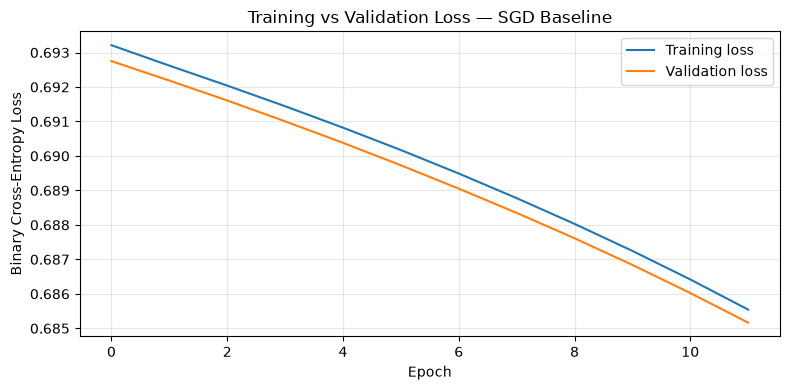

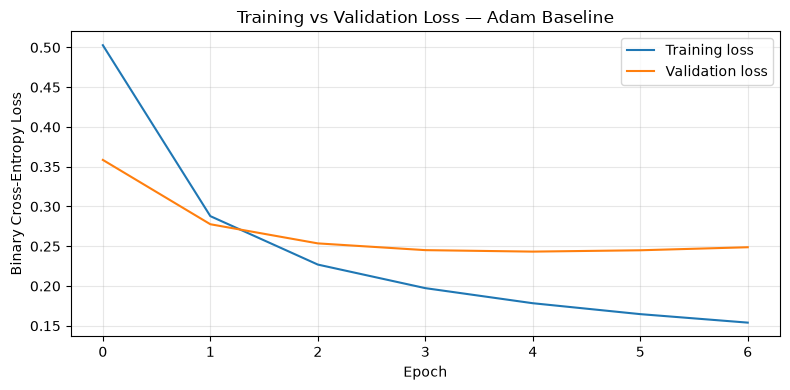

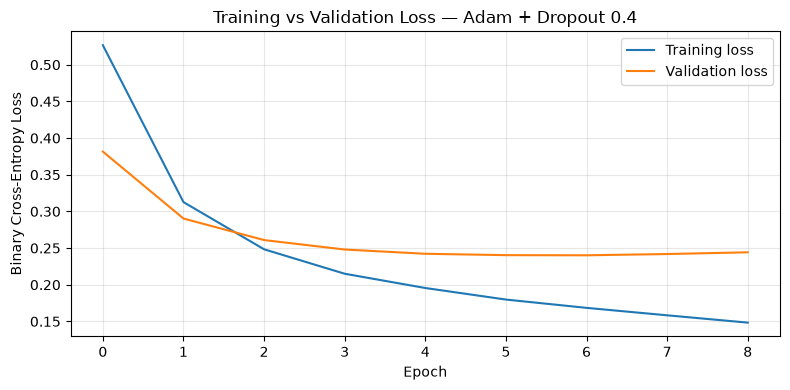

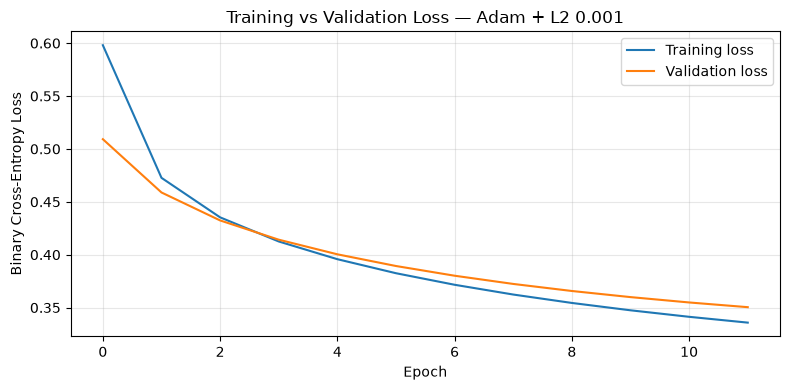

In [9]:
for name, history in histories.items():
    plt.figure(figsize=(8, 4))

    plt.plot(history["loss"], label="Training loss")
    plt.plot(history["val_loss"], label="Validation loss")

    plt.title(f"Training vs Validation Loss — {name}")
    plt.xlabel("Epoch")
    plt.ylabel("Binary Cross-Entropy Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [10]:
output_dir = root / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

mlp_results.to_csv(
    output_dir / "mlp_results.csv",
    index=False
)

print("MLP results saved to:", output_dir / "mlp_results.csv")
display(mlp_results)

MLP results saved to: c:\Users\poona\OneDrive\Desktop\parkh\outputs\mlp_results.csv


,Model,Test Accuracy,Test Loss,Best Validation Accuracy,Epochs Trained
0,Adam + Dropout 0.4,0.900915,0.234990,0.897032,9
1,Adam Baseline,0.898441,0.237988,0.895795,7
2,Adam + L2 0.001,0.894607,0.344581,0.883890,12
3,SGD Baseline,0.709550,0.684888,0.707483,12


In [11]:
output_dir = root / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

mlp_results.to_csv(output_dir / "mlp_results.csv", index=False)

print("Saved:", output_dir / "mlp_results.csv")
print("File exists:", (output_dir / "mlp_results.csv").exists())

Saved: c:\Users\poona\OneDrive\Desktop\parkh\outputs\mlp_results.csv
File exists: True


In [12]:
def build_mlp_extended(optimizer_name="adam", dropout_rate=0.0,
                       l2_strength=0.0, l1_strength=0.0):
    tf.keras.utils.set_random_seed(42)

    if optimizer_name == "sgd_momentum":
        optimizer = keras.optimizers.SGD(
            learning_rate=0.1,
            momentum=0.9
        )
    else:
        optimizer = keras.optimizers.Adam(learning_rate=0.001)

    model = keras.Sequential([
        keras.Input(shape=(5000,)),
        layers.Dense(
            64,
            activation="relu",
            kernel_regularizer=(
                regularizers.l1_l2(
                    l1=l1_strength,
                    l2=l2_strength
                )
                if l1_strength > 0 and l2_strength > 0
                else regularizers.l1(l1_strength)
                if l1_strength > 0
                else regularizers.l2(l2_strength)
                if l2_strength > 0
                else None
            )
        ),
        layers.Dropout(dropout_rate),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

print("Extended model builder is ready!")

Extended model builder is ready!


In [13]:
new_experiments = [
    {
        "name": "SGD (lr 0.1, momentum 0.9)",
        "optimizer": "sgd_momentum",
        "l1": 0.0
    },
    {
        "name": "Adam + L1 0.0001",
        "optimizer": "adam",
        "l1": 0.0001
    }
]

new_results = []
new_histories = {}
new_models = {}

for exp in new_experiments:
    print(f"\nTraining: {exp['name']}")

    model = build_mlp_extended(
        optimizer_name=exp["optimizer"],
        l1_strength=exp["l1"]
    )

    stopper = EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    history = model.fit(
        Xtr, ytr,
        validation_split=0.20,
        epochs=12,
        batch_size=256,
        callbacks=[stopper],
        verbose=1
    )

    test_loss, test_accuracy = model.evaluate(Xte, yte, verbose=0)

    new_results.append({
        "Model": exp["name"],
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss,
        "Best Validation Accuracy": max(history.history["val_accuracy"]),
        "Epochs Trained": len(history.history["loss"])
    })

    new_histories[exp["name"]] = history.history
    new_models[exp["name"]] = model

    print(f"Test accuracy: {test_accuracy:.4f}")

new_results_df = pd.DataFrame(new_results)

display(
    new_results_df.style.format({
        "Test Accuracy": "{:.2%}",
        "Test Loss": "{:.4f}",
        "Best Validation Accuracy": "{:.2%}"
    })
)


Training: SGD (lr 0.1, momentum 0.9)
Epoch 1/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7026 - loss: 0.6431 - val_accuracy: 0.8038 - val_loss: 0.5292
Epoch 2/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8361 - loss: 0.4081 - val_accuracy: 0.8488 - val_loss: 0.3485
Epoch 3/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8762 - loss: 0.2993 - val_accuracy: 0.8724 - val_loss: 0.2927
Epoch 4/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8957 - loss: 0.2540 - val_accuracy: 0.8813 - val_loss: 0.2699
Epoch 5/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9063 - loss: 0.2284 - val_accuracy: 0.8874 - val_loss: 0.2576
Epoch 6/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9148 - loss: 0.2107 - val_accuracy: 0.8935 - val_loss: 0.2508
Epoch 7/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9210 - loss: 0.1974 - val_accuracy: 0.8935 - val_loss: 0.2471
Epoch 8/12
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.

,Model,Test Accuracy,Test Loss,Best Validation Accuracy,Epochs Trained
0,"SGD (lr 0.1, momentum 0.9)",90.18%,0.2392,89.66%,11
1,Adam + L1 0.0001,86.92%,0.4306,85.78%,12


In [14]:
all_mlp_results = pd.concat(
    [mlp_results, new_results_df],
    ignore_index=True
)

all_mlp_results.to_csv(
    root / "outputs" / "mlp_results.csv",
    index=False
)

display(
    all_mlp_results.sort_values(
        "Test Accuracy", ascending=False
    ).reset_index(drop=True)
)

print("Updated MLP results saved.")

,Model,Test Accuracy,Test Loss,Best Validation Accuracy,Epochs Trained
0,"SGD (lr 0.1, momentum 0.9)",0.901781,0.239242,0.896568,11
1,Adam + Dropout 0.4,0.900915,0.234990,0.897032,9
2,Adam Baseline,0.898441,0.237988,0.895795,7
3,Adam + L2 0.001,0.894607,0.344581,0.883890,12
4,Adam + L1 0.0001,0.869248,0.430642,0.857761,12
5,SGD Baseline,0.709550,0.684888,0.707483,12


Updated MLP results saved.


In [15]:
saved_results = pd.read_csv(root / "outputs" / "mlp_results.csv")

print("Number of experiments:", len(saved_results))
display(
    saved_results.sort_values("Test Accuracy", ascending=False)
    .reset_index(drop=True)
)

Number of experiments: 6


,Model,Test Accuracy,Test Loss,Best Validation Accuracy,Epochs Trained
0,"SGD (lr 0.1, momentum 0.9)",0.901781,0.239242,0.896568,11
1,Adam + Dropout 0.4,0.900915,0.234990,0.897032,9
2,Adam Baseline,0.898441,0.237988,0.895795,7
3,Adam + L2 0.001,0.894607,0.344581,0.883890,12
4,Adam + L1 0.0001,0.869248,0.430642,0.857761,12
5,SGD Baseline,0.709550,0.684888,0.707483,12


In [16]:
regularization_experiments = [
    {"name": "Adam + L1 0.0001", "l1": 0.0001, "l2": 0.0},
    {"name": "Adam + L2 0.001", "l1": 0.0, "l2": 0.001},
]

regularization_results = []
regularization_histories = {}

for exp in regularization_experiments:
    print(f"\nTraining: {exp['name']}")

    model = build_mlp_extended(
        optimizer_name="adam",
        l1_strength=exp["l1"],
        l2_strength=exp["l2"]
    )

    stopper = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    history = model.fit(
        Xtr, ytr,
        validation_split=0.20,
        epochs=40,
        batch_size=256,
        callbacks=[stopper],
        verbose=1
    )

    test_loss, test_accuracy = model.evaluate(Xte, yte, verbose=0)

    regularization_results.append({
        "Model": exp["name"],
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss,
        "Best Validation Accuracy": max(history.history["val_accuracy"]),
        "Epochs Trained": len(history.history["loss"])
    })

    regularization_histories[exp["name"]] = history.history

regularization_results_df = pd.DataFrame(regularization_results)

display(
    regularization_results_df.style.format({
        "Test Accuracy": "{:.2%}",
        "Test Loss": "{:.4f}",
        "Best Validation Accuracy": "{:.2%}"
    })
)


Training: Adam + L1 0.0001
Epoch 1/40
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7915 - loss: 0.7225 - val_accuracy: 0.8128 - val_loss: 0.5867
Epoch 2/40
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8294 - loss: 0.5425 - val_accuracy: 0.8242 - val_loss: 0.5238
Epoch 3/40
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8401 - loss: 0.4995 - val_accuracy: 0.8324 - val_loss: 0.4999
Epoch 4/40
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8463 - loss: 0.4806 - val_accuracy: 0.8380 - val_loss: 0.4872
Epoch 5/40
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8500 - loss: 0.4691 - val_accuracy: 0.8395 - val_loss: 0.4786
Epoch 6/40
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8541 - loss: 0.4607 - val_accuracy: 0.8437 - val_loss: 0.4717
Epoch 7/40
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8584 - loss: 0.4535 - val_accuracy: 0.8462 - val_loss: 0.4657
Epoch 8/40
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8616 - los

,Model,Test Accuracy,Test Loss,Best Validation Accuracy,Epochs Trained
0,Adam + L1 0.0001,89.29%,0.3605,88.37%,40
1,Adam + L2 0.001,89.51%,0.3036,89.16%,40


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

y = y.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y.ravel()
)

rng = np.random.default_rng(42)

W1 = rng.normal(0, 0.5, (2, 8))
b1 = np.zeros((1, 8))

W2 = rng.normal(0, 0.5, (8, 1))
b2 = np.zeros((1, 1))

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Hidden-layer weights:", W1.shape)
print("Output-layer weights:", W2.shape)

Training shape: (800, 2)
Test shape: (200, 2)
Hidden-layer weights: (2, 8)
Output-layer weights: (8, 1)
